# Fraud Detection — Walkthrough

**Author:** Seyedmohammad (Ehsan) Ghoreishi  
**Focus:** fraud / risk / financial-crime analytics

This notebook walks through the full pipeline: data → EDA → features → model → cost-based threshold → evaluation.

The guiding principle: on data where fraud is ~1.7% of transactions, **accuracy is a trap**. We optimise for catching fraud while keeping customer friction low, and we choose the decision threshold from a business cost model.

> Install the package first (`pip install -e .` from the repo root) so the imports above resolve from any working directory.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import average_precision_score, classification_report
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split

from fraud_detection.data import generate_transactions
from fraud_detection.eda import summarise
from fraud_detection.evaluation import choose_threshold, cost_curve
from fraud_detection.features import FEATURES, RAW_COLUMNS
from fraud_detection.models import build_models

pd.set_option("display.float_format", lambda v: f"{v:.3f}")

## 1. The data

Real payment data is confidential, so we generate a synthetic dataset that reproduces genuine card-fraud patterns: heavy imbalance, night-time skew, velocity spikes, new devices, and foreign / far-from-home transactions.

In [2]:
df = generate_transactions(n=60_000, fraud_rate=0.017)
print(f"{len(df):,} transactions | fraud rate: {df.is_fraud.mean():.2%}")
df.head()

60,000 transactions | fraud rate: 1.70%


,amount,hour,days_since_last_txn,txn_count_1h,new_device,foreign_country,distance_from_home,merchant_risk,is_fraud
0,47.350,15,1.270,1,0,0,26.000,0.268,0
1,3.310,6,0.760,1,0,0,15.000,0.200,0
2,118.650,16,0.870,1,0,0,51.400,0.105,0
3,14.520,16,2.510,3,0,0,23.200,0.068,0
4,30.170,12,0.320,2,0,0,8.700,0.396,0


## 2. How does fraud differ from legit traffic?

Understanding the data before modelling. The differences are strong and intuitive.

In [3]:
summarise(df)

,legit,fraud
Median amount (€),19.975,69.995
Night transactions,0.032,0.416
New device,0.050,0.536
Foreign country,0.079,0.438


## 3. Split before anything is learned

The test set is put aside **now** and used exactly once at the end. Every
feature statistic, the model choice and the threshold are learned on the
training split only.

In [4]:
X, y = df[RAW_COLUMNS], df["is_fraud"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)
print(f"Train fraud rate: {y_train.mean():.2%} | Test fraud rate: {y_test.mean():.2%}")
print("Model features:", ", ".join(FEATURES))

Train fraud rate: 1.70% | Test fraud rate: 1.70%
Model features: log_amount, hour, is_night, days_since_last_txn, txn_count_1h, high_velocity, new_device, foreign_country, distance_from_home, geo_risk, merchant_risk, device_geo_amount_risk


## 4. Choose a model with cross-validation

Each candidate pipeline starts with the `FraudFeatures` transformer, so the
domain features (log amount, night flag, velocity, geo risk, combined
device-geo-amount risk) are re-learned inside every fold. Out-of-fold
**PR-AUC** — the right metric for rare events — picks the winner.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = build_models()
oof = {name: cross_val_predict(m, X_train, y_train, cv=cv,
                               method="predict_proba")[:, 1]
       for name, m in models.items()}
cv_scores = pd.Series({name: average_precision_score(y_train, p)
                       for name, p in oof.items()}, name="cv_pr_auc")
best = cv_scores.idxmax()
cv_scores

logistic_regression   0.990
random_forest         0.980
Name: cv_pr_auc, dtype: float64

## 5. The key decision: the threshold

A missed fraud costs ~€150; a false alarm ~€5. We pick the threshold that minimises expected cost on the **out-of-fold training predictions** — **not** the default 0.5.

In [6]:
threshold, cv_costs = choose_threshold(y_train, oof[best])
print(f"Cost-optimal threshold ({best}): {threshold:.2f}")

Cost-optimal threshold (logistic_regression): 0.77


## 6. Evaluate once on the held-out test set

In [7]:
model = models[best].fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, 1]
preds = (proba >= threshold).astype(int)
print(f"Test PR-AUC: {average_precision_score(y_test, proba):.4f}\n")
print(classification_report(y_test, preds, target_names=["legit", "fraud"], digits=3))

Test PR-AUC: 0.9904

              precision    recall  f1-score   support

       legit      1.000     0.997     0.998     14745
       fraud      0.841     0.976     0.904       255

    accuracy                          0.996     15000
   macro avg      0.920     0.987     0.951     15000
weighted avg      0.997     0.996     0.997     15000



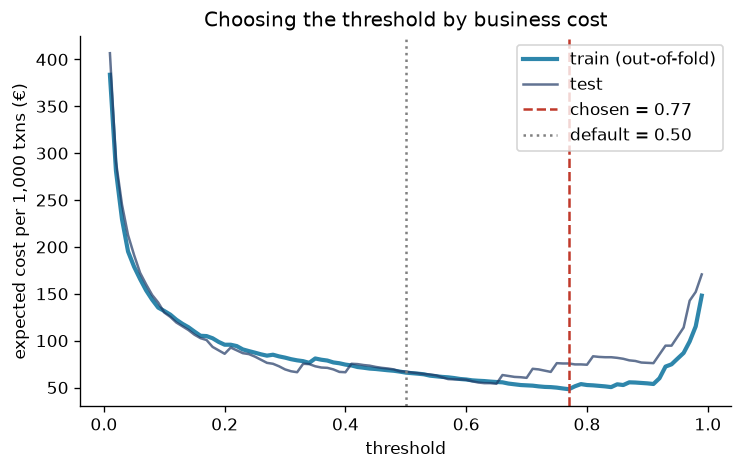

In [8]:
test_costs = cost_curve(y_test, proba)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cv_costs.threshold, cv_costs.cost / len(y_train) * 1000,
        color="#2E86AB", lw=2.5, label="train (out-of-fold)")
ax.plot(test_costs.threshold, test_costs.cost / len(y_test) * 1000,
        color="#1F3864", lw=1.5, alpha=0.7, label="test")
ax.axvline(threshold, color="#C0392B", ls="--", label=f"chosen = {threshold:.2f}")
ax.axvline(0.5, color="gray", ls=":", label="default = 0.50")
ax.set_xlabel("threshold")
ax.set_ylabel("expected cost per 1,000 txns (€)")
ax.set_title("Choosing the threshold by business cost")
ax.legend()
plt.show()

## Takeaway

The model catches **~98% of fraud** while flagging only ~2% of traffic,
measured on data that played no part in any decision. The cost curve is
flat over a wide band of thresholds, so the exact cut-off matters less than
the cost assumptions behind it — which is why the real deliverable isn't
the model but the **framework for the cost/coverage trade-off**, exactly
what a Customer Risk / AFC team owns day to day.